# Problem Description-Wallmart Sales Forecast

The objective of this project is to analyze Walmart sales data and build an end-to-end machine learning pipeline to identify key factors influencing sales and accurately forecast future demand, enabling data-driven decision-making and business optimization.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
import kagglehub
path = kagglehub.dataset_download("aslanahmedov/walmart-sales-forecast")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'walmart-sales-forecast' dataset.
Path to dataset files: /kaggle/input/walmart-sales-forecast


In [ ]:
df_train=pd.read_csv(path+r'/train.csv')
df_train

,Store,Dept,Date,Weekly_Sales,IsHoliday
0,1,1,2010-02-05,24924.50,False
1,1,1,2010-02-12,46039.49,True
2,1,1,2010-02-19,41595.55,False
3,1,1,2010-02-26,19403.54,False
4,1,1,2010-03-05,21827.90,False
...,...,...,...,...,...
421565,45,98,2012-09-28,508.37,False
421566,45,98,2012-10-05,628.10,False
421567,45,98,2012-10-12,1061.02,False
421568,45,98,2012-10-19,760.01,False


In [ ]:
df_test=pd.read_csv(path+r'/test.csv')
df_test

,Store,Dept,Date,IsHoliday
0,1,1,2012-11-02,False
1,1,1,2012-11-09,False
2,1,1,2012-11-16,False
3,1,1,2012-11-23,True
4,1,1,2012-11-30,False
...,...,...,...,...
115059,45,98,2013-06-28,False
115060,45,98,2013-07-05,False
115061,45,98,2013-07-12,False
115062,45,98,2013-07-19,False


In [ ]:
df1=pd.read_csv(path+r'/stores.csv')
df1.head()
#

,Store,Type,Size
0,1,A,151315
1,2,A,202307
2,3,B,37392
3,4,A,205863
4,5,B,34875


In [ ]:
df2=pd.read_csv(path+r'/features.csv')
df2

,Store,Date,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment,IsHoliday
0,1,2010-02-05,42.31,2.572,NaN,NaN,NaN,NaN,NaN,211.096358,8.106,False
1,1,2010-02-12,38.51,2.548,NaN,NaN,NaN,NaN,NaN,211.242170,8.106,True
2,1,2010-02-19,39.93,2.514,NaN,NaN,NaN,NaN,NaN,211.289143,8.106,False
3,1,2010-02-26,46.63,2.561,NaN,NaN,NaN,NaN,NaN,211.319643,8.106,False
4,1,2010-03-05,46.50,2.625,NaN,NaN,NaN,NaN,NaN,211.350143,8.106,False
...,...,...,...,...,...,...,...,...,...,...,...,...
8185,45,2013-06-28,76.05,3.639,4842.29,975.03,3.00,2449.97,3169.69,NaN,NaN,False
8186,45,2013-07-05,77.50,3.614,9090.48,2268.58,582.74,5797.47,1514.93,NaN,NaN,False
8187,45,2013-07-12,79.37,3.614,3789.94,1827.31,85.72,744.84,2150.36,NaN,NaN,False
8188,45,2013-07-19,82.84,3.737,2961.49,1047.07,204.19,363.00,1059.46,NaN,NaN,False


WE HAVE 4 DATASETS AND WE NEED TO MERGE THEM INTO ONE TO GET THE WEEKLYSALES FOR WALMART.
MAINLY TARGET COLUMN WILL BE PRESENT IN THE TRAINING DATASET AND NOT IN TESTING.
THIS IS THE HARD RULE.

****BY USING THE COMMON COLUMNS WE NEED TO MERGE THEM SAME AS SQL JOINS****


Here we merged the train part

In [ ]:
train_final = df_train.merge(
    df2,
    on=["Store", "Date"],
    how="left"
)

train_final = train_final.merge(
    df1,
    on="Store",
    how="left"
)


here we merge test part

In [ ]:
test_final = df_test.merge(
    df2,
    on=["Store", "Date"],
    how="left"
)

test_final = test_final.merge(
    df1,
    on="Store",
    how="left"
)


In [ ]:
train_final.head()

,Store,Dept,Date,Weekly_Sales,IsHoliday_x,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment,IsHoliday_y,Type,Size
0,1,1,2010-02-05,24924.50,False,42.31,2.572,NaN,NaN,NaN,NaN,NaN,211.096358,8.106,False,A,151315
1,1,1,2010-02-12,46039.49,True,38.51,2.548,NaN,NaN,NaN,NaN,NaN,211.242170,8.106,True,A,151315
2,1,1,2010-02-19,41595.55,False,39.93,2.514,NaN,NaN,NaN,NaN,NaN,211.289143,8.106,False,A,151315
3,1,1,2010-02-26,19403.54,False,46.63,2.561,NaN,NaN,NaN,NaN,NaN,211.319643,8.106,False,A,151315
4,1,1,2010-03-05,21827.90,False,46.50,2.625,NaN,NaN,NaN,NaN,NaN,211.350143,8.106,False,A,151315


In [ ]:
test_final.head()

,Store,Dept,Date,IsHoliday_x,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment,IsHoliday_y,Type,Size
0,1,1,2012-11-02,False,55.32,3.386,6766.44,5147.70,50.82,3639.90,2737.42,223.462779,6.573,False,A,151315
1,1,1,2012-11-09,False,61.24,3.314,11421.32,3370.89,40.28,4646.79,6154.16,223.481307,6.573,False,A,151315
2,1,1,2012-11-16,False,52.92,3.252,9696.28,292.10,103.78,1133.15,6612.69,223.512911,6.573,False,A,151315
3,1,1,2012-11-23,True,56.23,3.211,883.59,4.17,74910.32,209.91,303.32,223.561947,6.573,True,A,151315
4,1,1,2012-11-30,False,52.34,3.207,2460.03,NaN,3838.35,150.57,6966.34,223.610984,6.573,False,A,151315


I have copied the dataset inorder to lose anykind of columns.

In [ ]:
df_copy1=train_final.copy()

In [ ]:
df_copy1.shape

(421570, 17)

In [ ]:
df_copy1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 421570 entries, 0 to 421569
Data columns (total 17 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   Store         421570 non-null  int64  
 1   Dept          421570 non-null  int64  
 2   Date          421570 non-null  object 
 3   Weekly_Sales  421570 non-null  float64
 4   IsHoliday_x   421570 non-null  bool   
 5   Temperature   421570 non-null  float64
 6   Fuel_Price    421570 non-null  float64
 7   MarkDown1     150681 non-null  float64
 8   MarkDown2     111248 non-null  float64
 9   MarkDown3     137091 non-null  float64
 10  MarkDown4     134967 non-null  float64
 11  MarkDown5     151432 non-null  float64
 12  CPI           421570 non-null  float64
 13  Unemployment  421570 non-null  float64
 14  IsHoliday_y   421570 non-null  bool   
 15  Type          421570 non-null  object 
 16  Size          421570 non-null  int64  
dtypes: bool(2), float64(10), int64(3), object(2)
mem

In [ ]:
df_copy1['Date']=pd.to_datetime(df_copy1['Date'])

Converted date data type which was object to its original DATE data type.

In [ ]:
df_copy1.isnull().sum()

,0
Store,0
Dept,0
Date,0
Weekly_Sales,0
IsHoliday_x,0
Temperature,0
Fuel_Price,0
MarkDown1,270889
MarkDown2,310322
MarkDown3,284479


In [ ]:
df_copy1.isnull().sum().sum()

np.int64(1422431)

Here all the nulls are filled with '0' because they never happened in the sales.If any purchase would had spent then we need to do median.So,filling with zero is fine.
We can see that if the nulls are numeric we need to do mean and median and if the nulls are categorical we need to go with mode.

In [ ]:
Markdown_columns=['MarkDown1','MarkDown2','MarkDown3','MarkDown4','MarkDown5']
for i in Markdown_columns:
  df_copy1[i].fillna(0,inplace=True)


/tmp/ipykernel_629/4259682584.py:3: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_copy1[i].fillna(0,inplace=True)


In [ ]:
df_copy1.duplicated().sum()

np.int64(0)

There are no duplicates available.


Separating the date column into year,month,week because if we leave the date column as it is then it becomes problem to ml.So instead of ignoring we convert them and delete the date column.It is the best approach.

In [ ]:
def add_date_features(df):
    df["Year"] = df["Date"].dt.year
    df["Month"] = df["Date"].dt.month
    df["Week"] = df["Date"].dt.isocalendar().week.astype(int)
    df.drop("Date", axis=1, inplace=True)
    return df
df_copy1 = add_date_features(df_copy1)

In [ ]:
df_copy1.head()

,Store,Dept,Weekly_Sales,IsHoliday_x,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment,IsHoliday_y,Type,Size,Year,Month,Week
0,1,1,24924.50,False,42.31,2.572,0.0,0.0,0.0,0.0,0.0,211.096358,8.106,False,A,151315,2010,2,5
1,1,1,46039.49,True,38.51,2.548,0.0,0.0,0.0,0.0,0.0,211.242170,8.106,True,A,151315,2010,2,6
2,1,1,41595.55,False,39.93,2.514,0.0,0.0,0.0,0.0,0.0,211.289143,8.106,False,A,151315,2010,2,7
3,1,1,19403.54,False,46.63,2.561,0.0,0.0,0.0,0.0,0.0,211.319643,8.106,False,A,151315,2010,2,8
4,1,1,21827.90,False,46.50,2.625,0.0,0.0,0.0,0.0,0.0,211.350143,8.106,False,A,151315,2010,3,9


In [ ]:
df_copy1.describe()

,Store,Dept,Weekly_Sales,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment,Size,Year,Month,Week
count,421570.000000,421570.000000,421570.000000,421570.000000,421570.000000,421570.000000,421570.000000,421570.000000,421570.000000,421570.000000,421570.000000,421570.000000,421570.000000,421570.000000,421570.000000,421570.000000
mean,22.200546,44.260317,15981.258123,60.090059,3.361027,2590.074819,879.974298,468.087665,1083.132268,1662.772385,171.201947,7.960289,136727.915739,2010.968591,6.449510,25.826762
std,12.785297,30.492054,22711.183519,18.447931,0.458515,6052.385934,5084.538801,5528.873453,3894.529945,4207.629321,39.159276,1.863296,60980.583328,0.796876,3.243217,14.151887
min,1.000000,1.000000,-4988.940000,-2.060000,2.472000,0.000000,-265.760000,-29.100000,0.000000,0.000000,126.064000,3.879000,34875.000000,2010.000000,1.000000,1.000000
25%,11.000000,18.000000,2079.650000,46.680000,2.933000,0.000000,0.000000,0.000000,0.000000,0.000000,132.022667,6.891000,93638.000000,2010.000000,4.000000,14.000000
50%,22.000000,37.000000,7612.030000,62.090000,3.452000,0.000000,0.000000,0.000000,0.000000,0.000000,182.318780,7.866000,140167.000000,2011.000000,6.000000,26.000000
75%,33.000000,74.000000,20205.852500,74.280000,3.738000,2809.050000,2.200000,4.540000,425.290000,2168.040000,212.416993,8.572000,202505.000000,2012.000000,9.000000,38.000000
max,45.000000,99.000000,693099.360000,100.140000,4.468000,88646.760000,104519.540000,141630.610000,67474.850000,108519.280000,227.232807,14.313000,219622.000000,2012.000000,12.000000,52.000000


Here the data is distributed in its own manner.for every value they got assigned with different values.

Checking the monthly to weekly sales and aslo with holidays.

In [ ]:
df_copy1.groupby('Month')['Weekly_Sales'].mean()


,Weekly_Sales
Month,
1,14126.075111
2,16008.779217
3,15416.657597
4,15650.338357
5,15776.337202
6,16326.137002
7,15861.419650
8,16062.516933
9,15095.886154


These are the average sales.We can see that for except 4 months the rest of the month sales are almost similar with small difference only.
There is a seasonal pattern for customer demand.

In [ ]:
df_copy1.groupby('IsHoliday_y')['Weekly_Sales'].mean()

,Weekly_Sales
IsHoliday_y,
False,15901.445069
True,17035.823187


The average weekly sales during holiday weeks (17,000) are higher than during non-holiday weeks (15,901), indicating that holidays have a positive impact on sales.

In [ ]:
df_copy1.groupby("Store")["Weekly_Sales"].agg(["mean","median","count"])


,mean,median,count
Store,,,
1,21710.543621,10289.375,10244
2,26898.070031,14333.530,10238
3,6373.033983,2804.815,9036
4,29161.210415,15116.810,10272
5,5053.415813,2582.660,8999
6,21913.243624,13637.840,10211
7,8358.766148,4575.240,9762
8,13133.014768,7164.160,9895
9,8772.890379,4205.470,8867


We have mean,median and count for every store weekly sales they are either increasing due to customer demand or decreasing due to the off season.

Checking the corelations for specific numerical columns.

In [ ]:
df_copy1[['Weekly_Sales','Size']].corr()

,Weekly_Sales,Size
Weekly_Sales,1.000000,0.243828
Size,0.243828,1.000000


Weekly sales show a weak positive correlation with Store_Size.

In [ ]:
df_copy1[['Weekly_Sales','Temperature']].corr()

,Weekly_Sales,Temperature
Weekly_Sales,1.000000,-0.002312
Temperature,-0.002312,1.000000


Weekly sales show a very weak neagtive corealtion with temperature.
These are some insights and we can do lots of eda using the data.

Doing the visualisation part for the data using matplotlib and seaborn.

<Axes: xlabel='Year'>

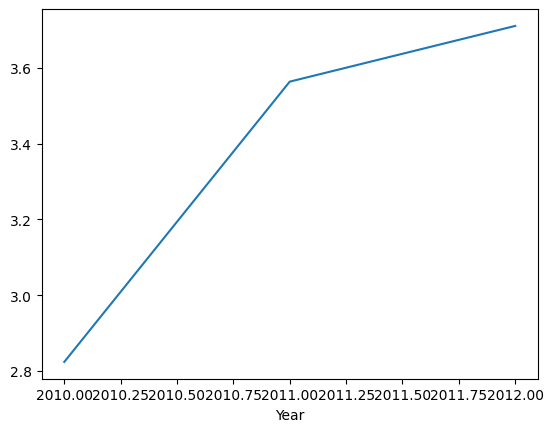

In [ ]:
df_copy1.groupby('Year')['Fuel_Price'].mean().plot()

Average fuel prices show an increasing trend from 2010 to 2012, indicating rising transportation and energy costs over time.

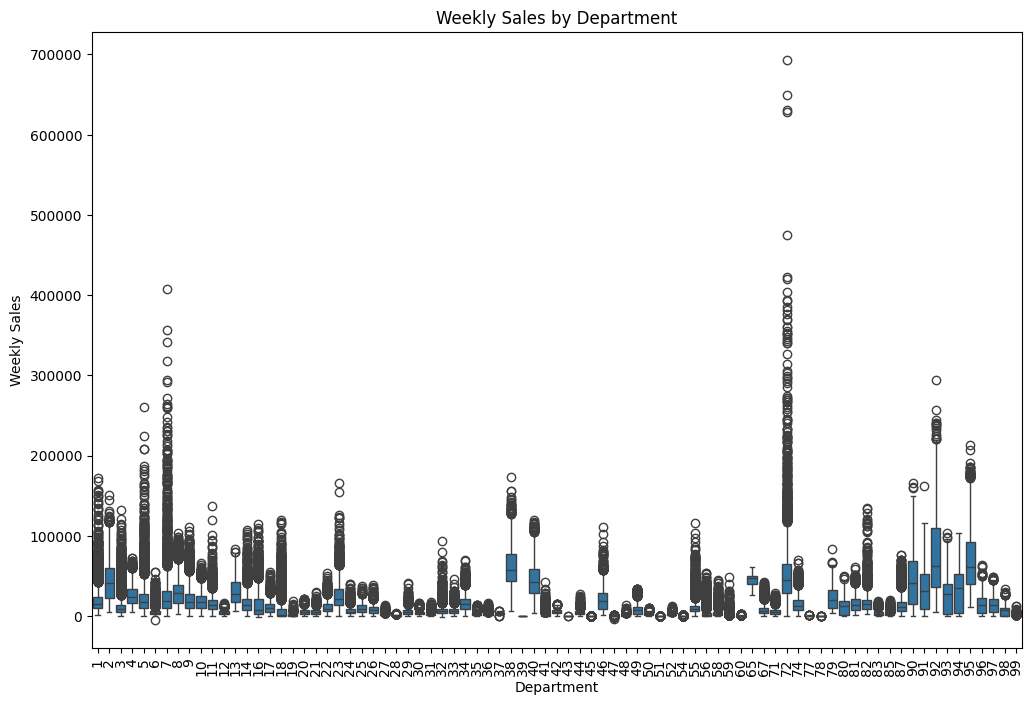

In [ ]:
plt.figure(figsize=(12,8))
sns.boxplot(x=df_copy1['Dept'],y=df_copy1['Weekly_Sales'])
plt.xlabel('Department')
plt.ylabel('Weekly Sales')
plt.title('Weekly Sales by Department')
plt.xticks(rotation=90)
plt.show()

Weekly sales vary significantly across departments, with some departments showing much higher median sales and greater variability than others. Several departments exhibit extreme outliers, indicating department-specific demand patterns and sales spikes.

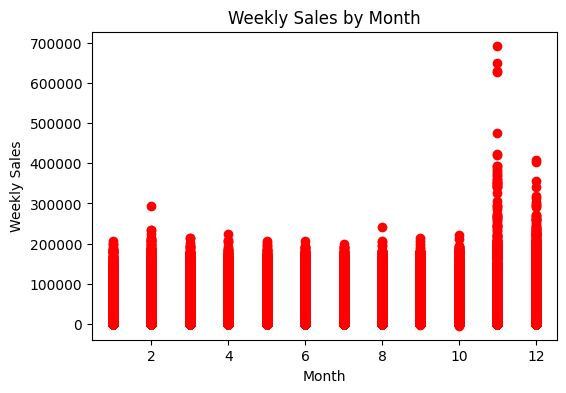

In [ ]:
plt.figure(figsize=(6,4))
plt.scatter(df_copy1['Month'],df_copy1['Weekly_Sales'],color='red')
plt.xlabel('Month')
plt.ylabel('Weekly Sales')
plt.title('Weekly Sales by Month')
plt.show()

Weekly Sales are bascially in a same fluctuations but slightly they are increasing or decreasing but in november month the sales increassed at the highest due to the demnad or season and started decresing slightly in december aqain.

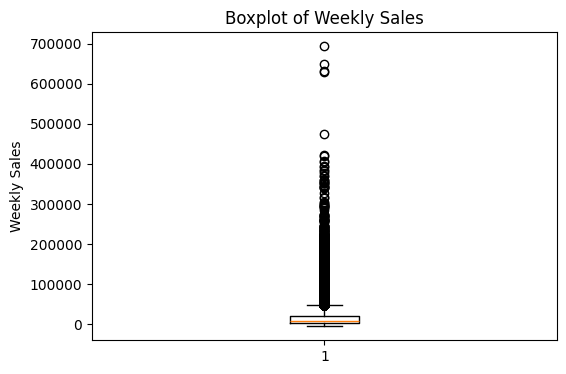

In [ ]:
plt.figure(figsize=(6,4))
plt.boxplot(df_copy1['Weekly_Sales'])
plt.ylabel('Weekly Sales')
plt.title('Boxplot of Weekly Sales')
plt.show()

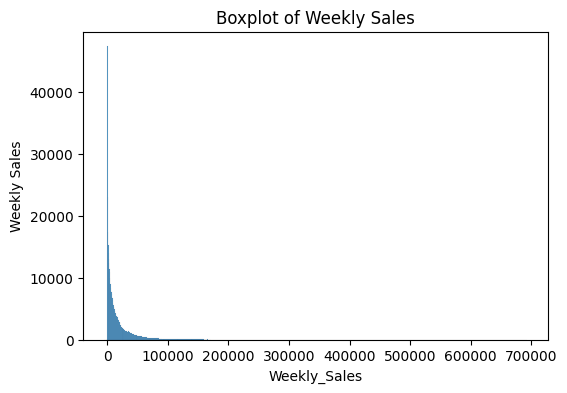

In [ ]:
plt.figure(figsize=(6,4))
sns.histplot(x=df_copy1['Weekly_Sales'])
plt.ylabel('Weekly Sales')
plt.title('Boxplot of Weekly Sales')
plt.show()

In [ ]:
num_cols=df_copy1.select_dtypes(include='number')

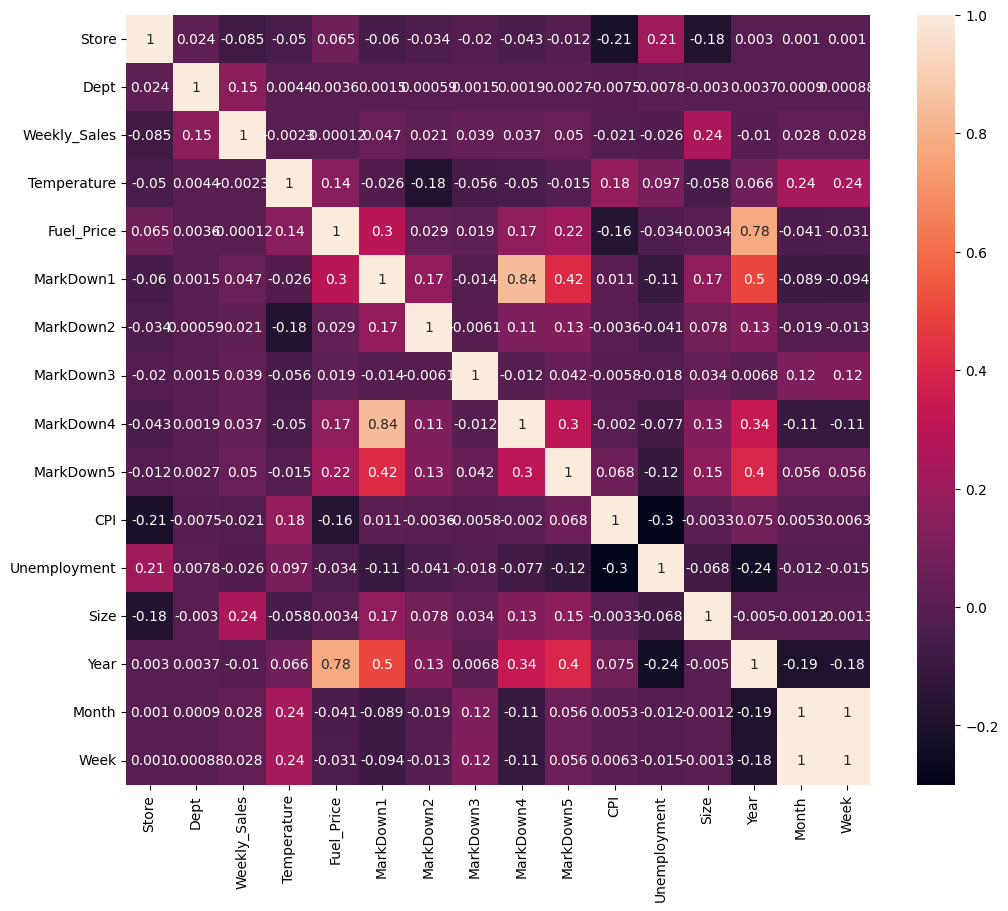

In [ ]:
plt.figure(figsize=(12,10))
sns.heatmap(num_cols.corr(),annot=True)
plt.show()

Basically heatmap generates corelation from -1,0,1 where the relationship stands.So,we check the realtion using the target column which is WeeklySales.
If it is -1 then strong negative co relation,0 means linear relation,+1 means strong positive corelation based on this we measure the corelations of the columns.

'Checking for outliers'

In [ ]:
df_copy1.columns

Index(['Store', 'Dept', 'Weekly_Sales', 'IsHoliday_x', 'Temperature',
       'Fuel_Price', 'MarkDown1', 'MarkDown2', 'MarkDown3', 'MarkDown4',
       'MarkDown5', 'CPI', 'Unemployment', 'IsHoliday_y', 'Type', 'Size',
       'Year', 'Month', 'Week'],
      dtype='object')

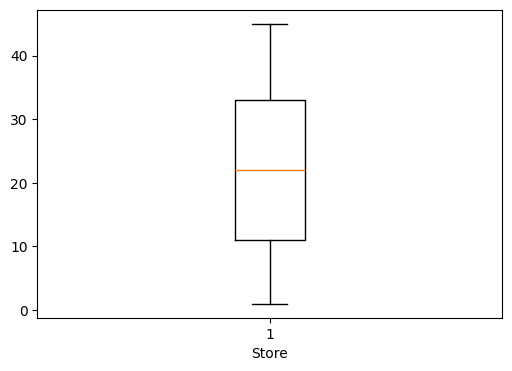

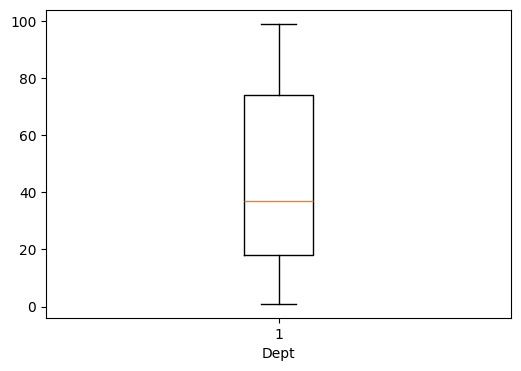

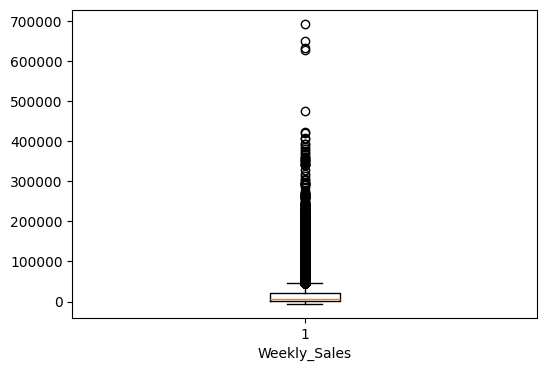

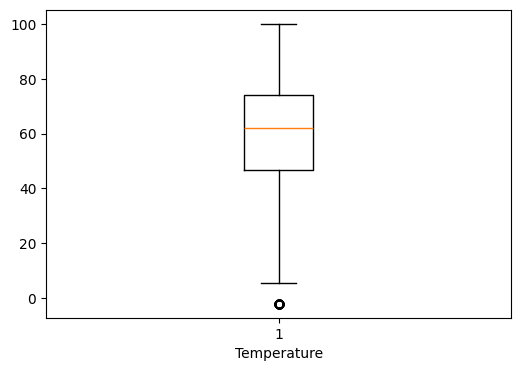

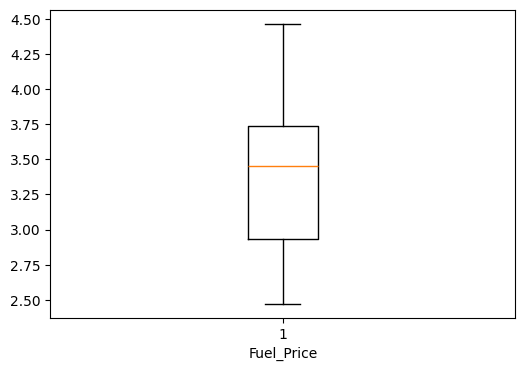

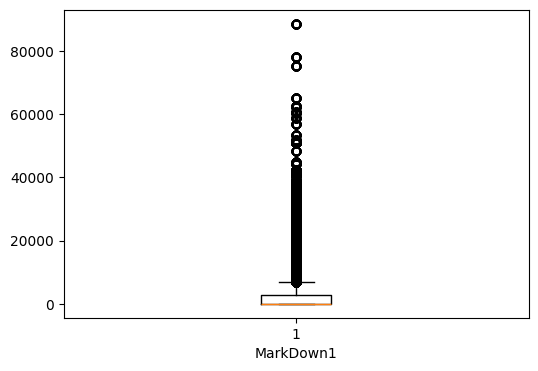

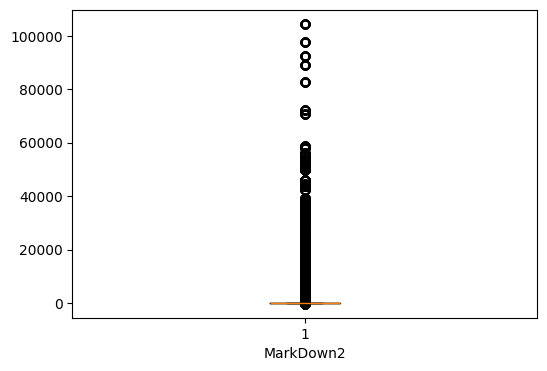

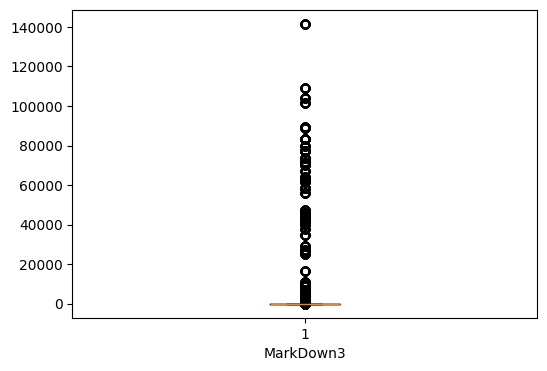

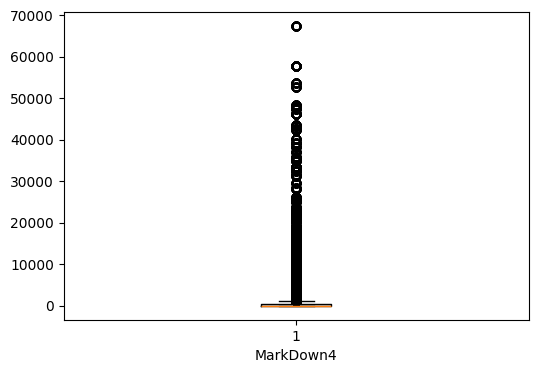

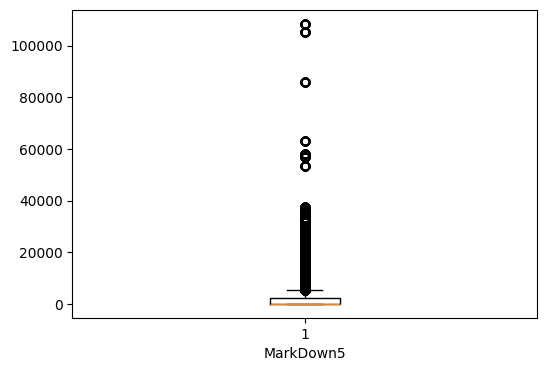

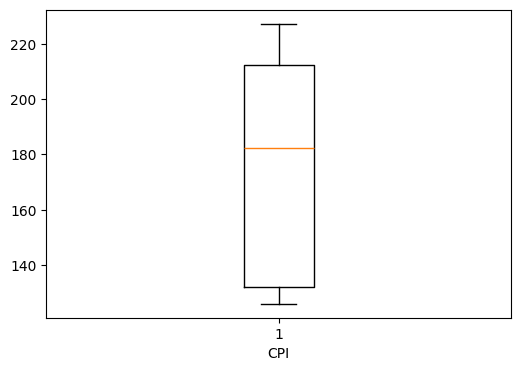

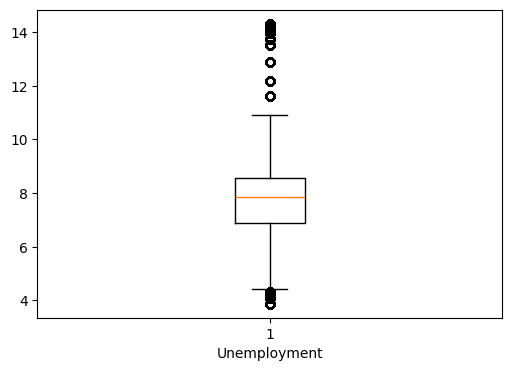

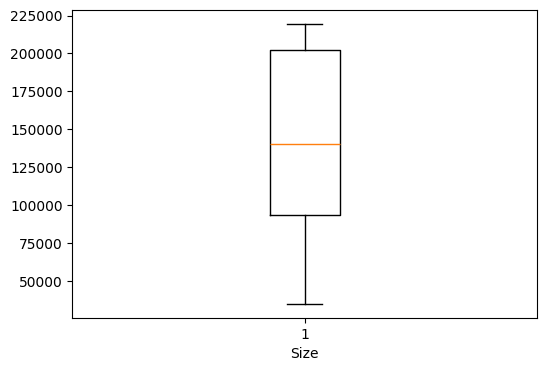

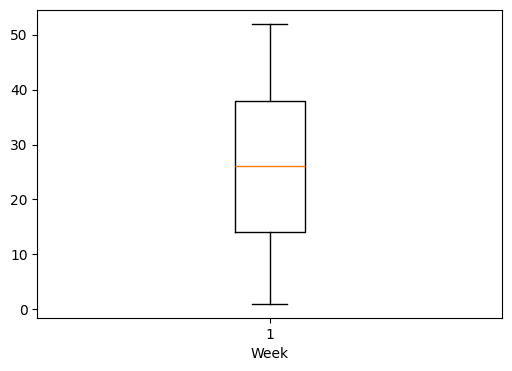

In [ ]:
for i in df_copy1.columns:
  if df_copy1[i].dtype=='int64' or df_copy1[i].dtype=='float64':
    plt.figure(figsize=(6,4))
    plt.boxplot(df_copy1[i])
    plt.xlabel(i)
    plt.show()

Outliers were identified in numerical features. As these values reflect real business behavior and tree-based models handle outliers effectively, no outlier removal was performed.

Performing Inferential_Statistics

In [ ]:
num_cols

,Store,Dept,Weekly_Sales,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment,Size,Year,Month,Week
0,1,1,24924.50,42.31,2.572,0.00,0.00,0.00,0.00,0.00,211.096358,8.106,151315,2010,2,5
1,1,1,46039.49,38.51,2.548,0.00,0.00,0.00,0.00,0.00,211.242170,8.106,151315,2010,2,6
2,1,1,41595.55,39.93,2.514,0.00,0.00,0.00,0.00,0.00,211.289143,8.106,151315,2010,2,7
3,1,1,19403.54,46.63,2.561,0.00,0.00,0.00,0.00,0.00,211.319643,8.106,151315,2010,2,8
4,1,1,21827.90,46.50,2.625,0.00,0.00,0.00,0.00,0.00,211.350143,8.106,151315,2010,3,9
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
421565,45,98,508.37,64.88,3.997,4556.61,20.64,1.50,1601.01,3288.25,192.013558,8.684,118221,2012,9,39
421566,45,98,628.10,64.89,3.985,5046.74,0.00,18.82,2253.43,2340.01,192.170412,8.667,118221,2012,10,40
421567,45,98,1061.02,54.47,4.000,1956.28,0.00,7.89,599.32,3990.54,192.327265,8.667,118221,2012,10,41
421568,45,98,760.01,56.47,3.969,2004.02,0.00,3.18,437.73,1537.49,192.330854,8.667,118221,2012,10,42


In [ ]:
from scipy.stats import pearsonr

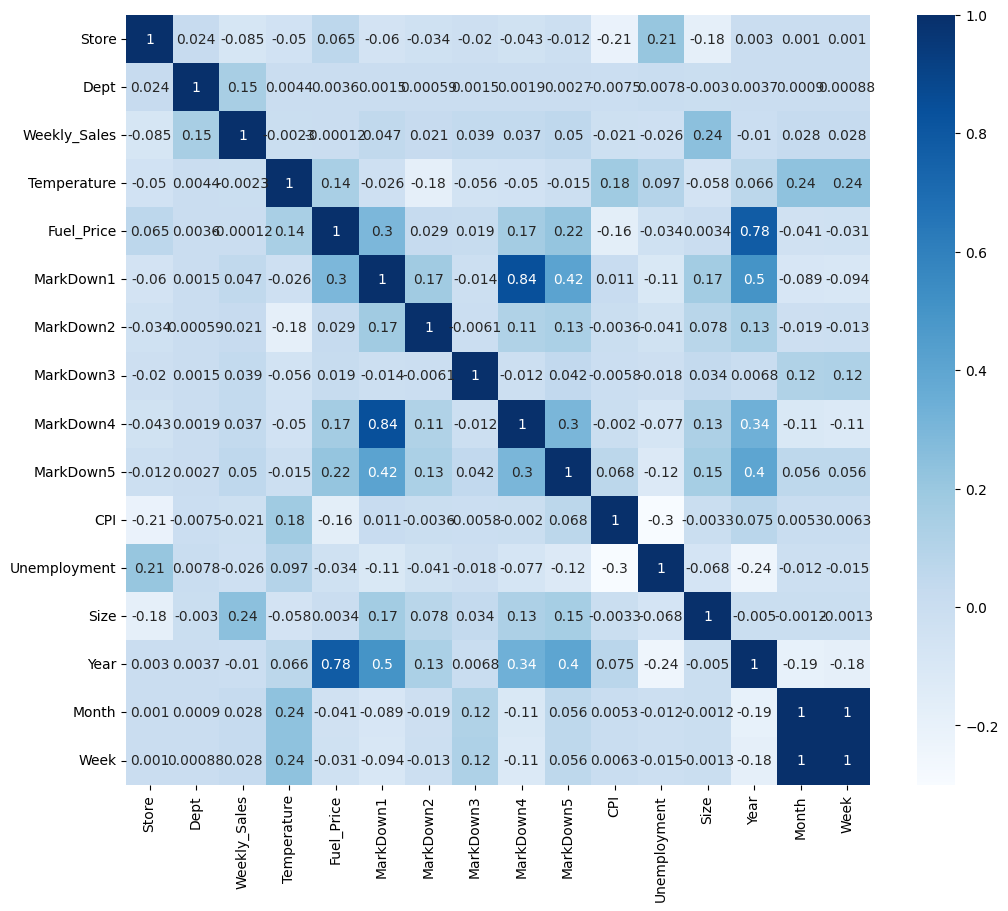

In [ ]:
corr=num_cols.corr(method='pearson')
plt.figure(figsize=(12,10))
sns.heatmap(corr,annot=True,cmap='Blues')
plt.show()

Pearson correlation analysis was performed on numerical features to examine linear relationships with the target variable. Boolean variables were excluded from the Pearson analysis and were analyzed separately using group-wise comparisons.
Corelation lies between -1 to 1.


Pearson analysis works for -1 and 1 through having values close to +1 indicate strong positive corelation and values close to -1 indicate strong negative corelation and 0 indicates the linear relationship.

CHI2 test cannot be performed for this data becuase there are no categorical columns available.So we reject this this test.



MACHINE LEARNING

In [ ]:
df_copy1.head()

,Store,Dept,Weekly_Sales,IsHoliday_x,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment,IsHoliday_y,Type,Size,Year,Month,Week
0,1,1,24924.50,False,42.31,2.572,0.0,0.0,0.0,0.0,0.0,211.096358,8.106,False,A,151315,2010,2,5
1,1,1,46039.49,True,38.51,2.548,0.0,0.0,0.0,0.0,0.0,211.242170,8.106,True,A,151315,2010,2,6
2,1,1,41595.55,False,39.93,2.514,0.0,0.0,0.0,0.0,0.0,211.289143,8.106,False,A,151315,2010,2,7
3,1,1,19403.54,False,46.63,2.561,0.0,0.0,0.0,0.0,0.0,211.319643,8.106,False,A,151315,2010,2,8
4,1,1,21827.90,False,46.50,2.625,0.0,0.0,0.0,0.0,0.0,211.350143,8.106,False,A,151315,2010,3,9


First of all we have 2 isholiday columns X and Y which is from multiple datasets so we can drop one column which is from test dataset i.e Y and keep the x column in the dataset.

In [ ]:
df_copy1.drop('IsHoliday_y',axis=1,inplace=True)

In [ ]:
df_copy1.rename(columns={'IsHoliday_x':'IsHoliday'},inplace=True)

In [ ]:
df_copy1

,Store,Dept,Weekly_Sales,IsHoliday,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment,Type,Size,Year,Month,Week
0,1,1,24924.50,False,42.31,2.572,0.00,0.00,0.00,0.00,0.00,211.096358,8.106,A,151315,2010,2,5
1,1,1,46039.49,True,38.51,2.548,0.00,0.00,0.00,0.00,0.00,211.242170,8.106,A,151315,2010,2,6
2,1,1,41595.55,False,39.93,2.514,0.00,0.00,0.00,0.00,0.00,211.289143,8.106,A,151315,2010,2,7
3,1,1,19403.54,False,46.63,2.561,0.00,0.00,0.00,0.00,0.00,211.319643,8.106,A,151315,2010,2,8
4,1,1,21827.90,False,46.50,2.625,0.00,0.00,0.00,0.00,0.00,211.350143,8.106,A,151315,2010,3,9
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
421565,45,98,508.37,False,64.88,3.997,4556.61,20.64,1.50,1601.01,3288.25,192.013558,8.684,B,118221,2012,9,39
421566,45,98,628.10,False,64.89,3.985,5046.74,0.00,18.82,2253.43,2340.01,192.170412,8.667,B,118221,2012,10,40
421567,45,98,1061.02,False,54.47,4.000,1956.28,0.00,7.89,599.32,3990.54,192.327265,8.667,B,118221,2012,10,41
421568,45,98,760.01,False,56.47,3.969,2004.02,0.00,3.18,437.73,1537.49,192.330854,8.667,B,118221,2012,10,42


Converting boolean column into integer using map command.

In [ ]:
df_copy1['IsHoliday']=df_copy1['IsHoliday'].map({True:1,False:0})

We have 1 column as object as alphabets we need to do onehotencoding which divides every value into binary values of each element.
There is no correct order for it so we cannot perform label encoding.

In [ ]:
df_copy1=pd.get_dummies(df_copy1,columns=['Type'],drop_first=True)

In [ ]:
df_copy1.head()

,Store,Dept,Weekly_Sales,IsHoliday,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment,Size,Year,Month,Week,Type_B,Type_C
0,1,1,24924.50,0,42.31,2.572,0.0,0.0,0.0,0.0,0.0,211.096358,8.106,151315,2010,2,5,False,False
1,1,1,46039.49,1,38.51,2.548,0.0,0.0,0.0,0.0,0.0,211.242170,8.106,151315,2010,2,6,False,False
2,1,1,41595.55,0,39.93,2.514,0.0,0.0,0.0,0.0,0.0,211.289143,8.106,151315,2010,2,7,False,False
3,1,1,19403.54,0,46.63,2.561,0.0,0.0,0.0,0.0,0.0,211.319643,8.106,151315,2010,2,8,False,False
4,1,1,21827.90,0,46.50,2.625,0.0,0.0,0.0,0.0,0.0,211.350143,8.106,151315,2010,3,9,False,False


After doing one hot encoding the columns got there separate boolean values by eliminating one dummy column using drop_first=True for reducing multicolinearity.

In [ ]:
#df_copy1['Type_B']=df_copy1['Type_B'].map({True:1,False:0})
#df_copy1['Type_C']=df_copy1['Type_C'].map({True:1,False:0})

In [ ]:
df_copy1["Type_B"] = (
    df_copy1["Type_B"]
    .fillna(False)
    .map({True: 1, False: 0})
)

df_copy1["Type_C"] = (
    df_copy1["Type_C"]
    .fillna(False)
    .map({True: 1, False: 0})
)


In [ ]:
df_copy1.head()

,Store,Dept,Weekly_Sales,IsHoliday,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment,Size,Year,Month,Week,Type_B,Type_C
0,1,1,24924.50,0,42.31,2.572,0.0,0.0,0.0,0.0,0.0,211.096358,8.106,151315,2010,2,5,0,0
1,1,1,46039.49,1,38.51,2.548,0.0,0.0,0.0,0.0,0.0,211.242170,8.106,151315,2010,2,6,0,0
2,1,1,41595.55,0,39.93,2.514,0.0,0.0,0.0,0.0,0.0,211.289143,8.106,151315,2010,2,7,0,0
3,1,1,19403.54,0,46.63,2.561,0.0,0.0,0.0,0.0,0.0,211.319643,8.106,151315,2010,2,8,0,0
4,1,1,21827.90,0,46.50,2.625,0.0,0.0,0.0,0.0,0.0,211.350143,8.106,151315,2010,3,9,0,0


In [ ]:
df_copy1['Type_B'].isnull().sum()

np.int64(0)

In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
X=df_copy1.drop('Weekly_Sales',axis=1)
y=df_copy1['Weekly_Sales']

In [ ]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)


In [ ]:
X_train.shape

(337256, 18)

In [ ]:
y_train.shape

(337256,)

Now performing linear regression for a baseline


In [ ]:
from sklearn.linear_model import LinearRegression

In [ ]:
lr=LinearRegression()
lr.fit(X_train,y_train)

LinearRegression()

In [ ]:
y_pred=lr.predict(X_test)

In [ ]:
from sklearn.metrics import *

In [ ]:
r2_score(y_test,y_pred)

0.09262597024152686

In [ ]:
mean_absolute_error(y_test,y_pred)

14561.354166834162

In [ ]:
mean_squared_error(y_test,y_pred)

473169236.20964456

In [ ]:
y_train_pred=lr.predict(X_train)

In [ ]:
r2_score(y_train,y_train_pred)

0.09011018308436403

In [ ]:
mean_absolute_error(y_train,y_train_pred)


14554.634520979529

In [ ]:
mean_squared_error(y_train,y_train_pred)

468027324.90493935

The model achieved similar performance on training and validation data, indicating good generalization with no signs of overfitting. However, the low R² score suggests that the model underfits the data and does not fully capture the complex sales patterns present in the dataset.

We need to perform randomforest regressor or boosting echniques in order to get correct picture of the model.

For better analysis we need to find more values like previous sales for separate columns.

In [ ]:
df_copy1=df_copy1.sort_values(['Store','Dept','Year','Week'])

df_copy1['lag_1']=df_copy1.groupby(['Store','Dept'])['Weekly_Sales'].shift(1)

df_copy1['lag_2']=df_copy1.groupby(['Store','Dept'])['Weekly_Sales'].shift(2)

In [ ]:
df_copy1.head()

,Store,Dept,Weekly_Sales,IsHoliday,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,...,CPI,Unemployment,Size,Year,Month,Week,Type_B,Type_C,lag_1,lag_2
0,1,1,24924.50,0,42.31,2.572,0.0,0.0,0.0,0.0,...,211.096358,8.106,151315,2010,2,5,0,0,NaN,NaN
1,1,1,46039.49,1,38.51,2.548,0.0,0.0,0.0,0.0,...,211.242170,8.106,151315,2010,2,6,0,0,24924.50,NaN
2,1,1,41595.55,0,39.93,2.514,0.0,0.0,0.0,0.0,...,211.289143,8.106,151315,2010,2,7,0,0,46039.49,24924.50
3,1,1,19403.54,0,46.63,2.561,0.0,0.0,0.0,0.0,...,211.319643,8.106,151315,2010,2,8,0,0,41595.55,46039.49
4,1,1,21827.90,0,46.50,2.625,0.0,0.0,0.0,0.0,...,211.350143,8.106,151315,2010,3,9,0,0,19403.54,41595.55


In [ ]:
df_copy1['lag_1'].isnull().sum()

np.int64(3331)

In [ ]:
df_copy1['lag_2'].isnull().sum()

np.int64(6625)

When we do the shift for getting the previous sales we usually get null values because for the starting week we will not have previous sales.Fixing of null values is done here.


In [ ]:
df_copy1['lag_1']=df_copy1['lag_1'].fillna(0)
df_copy1['lag_2']=df_copy1['lag_2'].fillna(0)

In [ ]:
df_copy1.head()

,Store,Dept,Weekly_Sales,IsHoliday,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,...,CPI,Unemployment,Size,Year,Month,Week,Type_B,Type_C,lag_1,lag_2
0,1,1,24924.50,0,42.31,2.572,0.0,0.0,0.0,0.0,...,211.096358,8.106,151315,2010,2,5,0,0,0.00,0.00
1,1,1,46039.49,1,38.51,2.548,0.0,0.0,0.0,0.0,...,211.242170,8.106,151315,2010,2,6,0,0,24924.50,0.00
2,1,1,41595.55,0,39.93,2.514,0.0,0.0,0.0,0.0,...,211.289143,8.106,151315,2010,2,7,0,0,46039.49,24924.50
3,1,1,19403.54,0,46.63,2.561,0.0,0.0,0.0,0.0,...,211.319643,8.106,151315,2010,2,8,0,0,41595.55,46039.49
4,1,1,21827.90,0,46.50,2.625,0.0,0.0,0.0,0.0,...,211.350143,8.106,151315,2010,3,9,0,0,19403.54,41595.55


In [ ]:
X=df_copy1.drop('Weekly_Sales',axis=1)
y=df_copy1['Weekly_Sales']
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

We split the data again because we added to new feature column.

In [ ]:
X_train.shape

(337256, 20)

In [ ]:
X_test.shape

(84314, 20)

In [ ]:
from sklearn.ensemble import RandomForestRegressor

In [ ]:
rf=RandomForestRegressor(n_estimators=50,max_depth=10,random_state=42)
rf.fit(X_train,y_train)

RandomForestRegressor(max_depth=10, n_estimators=50, random_state=42)

In [ ]:
y_pred=rf.predict(X_test)

In [ ]:
r2_score(y_test,y_pred)

0.9514373729862585

In [ ]:
mean_absolute_error(y_test,y_pred)

1870.02424770277

In [ ]:
mean_squared_error(y_test,y_pred)

25324001.32560805

In [ ]:
y_pred_train=rf.predict(X_train)

In [ ]:
r2_score(y_train,y_pred_train)

0.9659211501588447

In [ ]:
mean_absolute_error(y_train,y_pred_train)

1758.2216371213995

In [ ]:
mean_squared_error(y_train,y_pred_train)

17529411.3973713

We performed r2_score for trainging and testing and there is no much difference in both of them where training got value as 0.96 and testing got value as 0.95.This means a minimal overfitting is obtained here.
If the train is higher than test then its called overfitting.
If training and testing both comes low then it is called underfitting.

Performing Gradient boosting
boosting techniques basically performes in sequential manner where every model analyses and resolves the issue which is caused by the previous model.

In [ ]:
from sklearn.ensemble import GradientBoostingRegressor

In [ ]:
gb=GradientBoostingRegressor(n_estimators=100,learning_rate=0.1,max_depth=5,random_state=42)
gb.fit(X_train,y_train)

GradientBoostingRegressor(max_depth=5, random_state=42)

In [ ]:
y_pred_gb=gb.predict(X_test)

In [ ]:
r2_score(y_test,y_pred_gb)


0.9564297673446629

In [ ]:
mean_absolute_error(y_test,y_pred_gb)

1855.059846122528

In [ ]:
mean_squared_error(y_test,y_pred_gb)

22720612.482693594

In [ ]:
y_pred_train_gb=gb.predict(X_train)

In [ ]:
r2_score(y_train,y_pred_train_gb)

0.9628741659793616

In [ ]:
mean_absolute_error(y_train,y_pred_train_gb)

1789.2042015438255

In [ ]:
mean_squared_error(y_train,y_pred_train_gb)

19096713.0948288

The final regression model got r2 score as 0.96 for training and 0.95 as testing.There is only small difference of 0.1 with minimal overfitting the model is working fine withit.

Linear Regression performed poorly (R² = 0.09) due to inability to capture non-linear patterns
Random Forest significantly improved performance (R² = 0.95)
Gradient Boosting achieved the best results with lowest error and stable performance.

The high accuracy of the model helps in predicting future sales more reliably.
These predictions can be used for better inventory management.
It helps businesses avoid situations like overstocking or running out of products.

In [ ]:
df_copy1

,Store,Dept,Weekly_Sales,IsHoliday,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,...,CPI,Unemployment,Size,Year,Month,Week,Type_B,Type_C,lag_1,lag_2
0,1,1,24924.50,0,42.31,2.572,0.00,0.00,0.00,0.00,...,211.096358,8.106,151315,2010,2,5,0,0,0.00,0.00
1,1,1,46039.49,1,38.51,2.548,0.00,0.00,0.00,0.00,...,211.242170,8.106,151315,2010,2,6,0,0,24924.50,0.00
2,1,1,41595.55,0,39.93,2.514,0.00,0.00,0.00,0.00,...,211.289143,8.106,151315,2010,2,7,0,0,46039.49,24924.50
3,1,1,19403.54,0,46.63,2.561,0.00,0.00,0.00,0.00,...,211.319643,8.106,151315,2010,2,8,0,0,41595.55,46039.49
4,1,1,21827.90,0,46.50,2.625,0.00,0.00,0.00,0.00,...,211.350143,8.106,151315,2010,3,9,0,0,19403.54,41595.55
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
421565,45,98,508.37,0,64.88,3.997,4556.61,20.64,1.50,1601.01,...,192.013558,8.684,118221,2012,9,39,1,0,467.30,605.96
421566,45,98,628.10,0,64.89,3.985,5046.74,0.00,18.82,2253.43,...,192.170412,8.667,118221,2012,10,40,1,0,508.37,467.30
421567,45,98,1061.02,0,54.47,4.000,1956.28,0.00,7.89,599.32,...,192.327265,8.667,118221,2012,10,41,1,0,628.10,508.37
421568,45,98,760.01,0,56.47,3.969,2004.02,0.00,3.18,437.73,...,192.330854,8.667,118221,2012,10,42,1,0,1061.02,628.10


In [ ]:
df_copy1['Date'] = pd.to_datetime(df_copy1['Year'].astype(str) + '-W' + df_copy1['Week'].astype(str) + '-1', format='%Y-W%W-%w')

In [ ]:
df_copy1

,Store,Dept,Weekly_Sales,IsHoliday,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,...,Unemployment,Size,Year,Month,Week,Type_B,Type_C,lag_1,lag_2,Date
0,1,1,24924.50,0,42.31,2.572,0.00,0.00,0.00,0.00,...,8.106,151315,2010,2,5,0,0,0.00,0.00,2010-02-01
1,1,1,46039.49,1,38.51,2.548,0.00,0.00,0.00,0.00,...,8.106,151315,2010,2,6,0,0,24924.50,0.00,2010-02-08
2,1,1,41595.55,0,39.93,2.514,0.00,0.00,0.00,0.00,...,8.106,151315,2010,2,7,0,0,46039.49,24924.50,2010-02-15
3,1,1,19403.54,0,46.63,2.561,0.00,0.00,0.00,0.00,...,8.106,151315,2010,2,8,0,0,41595.55,46039.49,2010-02-22
4,1,1,21827.90,0,46.50,2.625,0.00,0.00,0.00,0.00,...,8.106,151315,2010,3,9,0,0,19403.54,41595.55,2010-03-01
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
421565,45,98,508.37,0,64.88,3.997,4556.61,20.64,1.50,1601.01,...,8.684,118221,2012,9,39,1,0,467.30,605.96,2012-09-24
421566,45,98,628.10,0,64.89,3.985,5046.74,0.00,18.82,2253.43,...,8.667,118221,2012,10,40,1,0,508.37,467.30,2012-10-01
421567,45,98,1061.02,0,54.47,4.000,1956.28,0.00,7.89,599.32,...,8.667,118221,2012,10,41,1,0,628.10,508.37,2012-10-08
421568,45,98,760.01,0,56.47,3.969,2004.02,0.00,3.18,437.73,...,8.667,118221,2012,10,42,1,0,1061.02,628.10,2012-10-15


Showing the seasonality trends through graphs with dates and weekly sales.

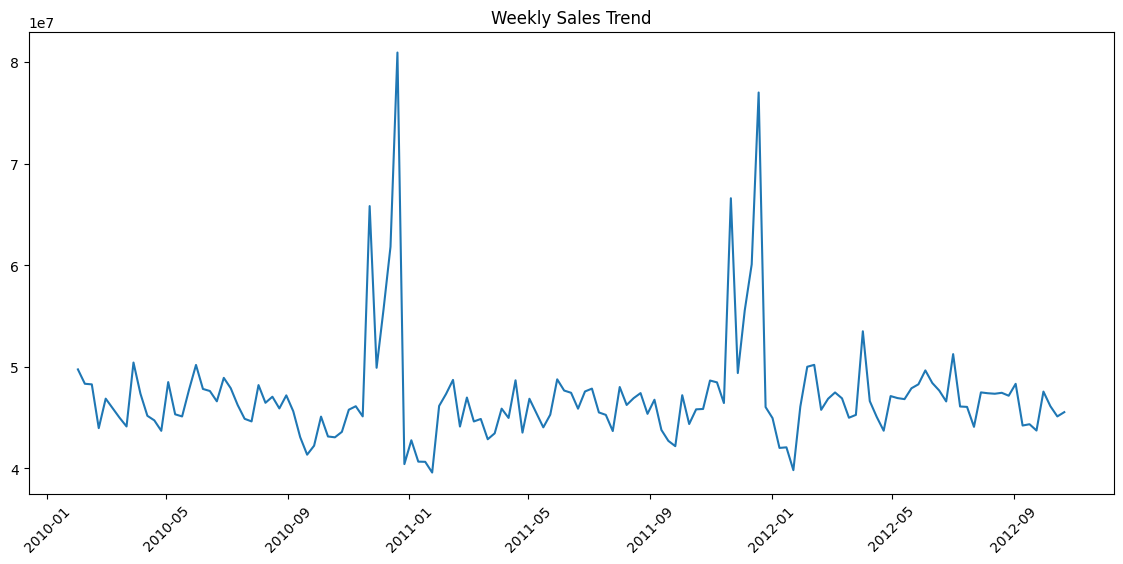

In [ ]:
plt.figure(figsize=(14,6))
plt.plot(df_copy1.groupby('Date')['Weekly_Sales'].sum())
plt.title("Weekly Sales Trend")
plt.xticks(rotation=45)
plt.show()

*   Sales exhibit noticeable spikes at certain time periods, indicating seasonal demand patterns.
*   Weekly sales show high variability, suggesting non-linear behavior in customer demand.
*   Peaks in sales are likely associated with holiday periods and special events.






Performing Actual vs Predicted graphs where training and testing is performed.

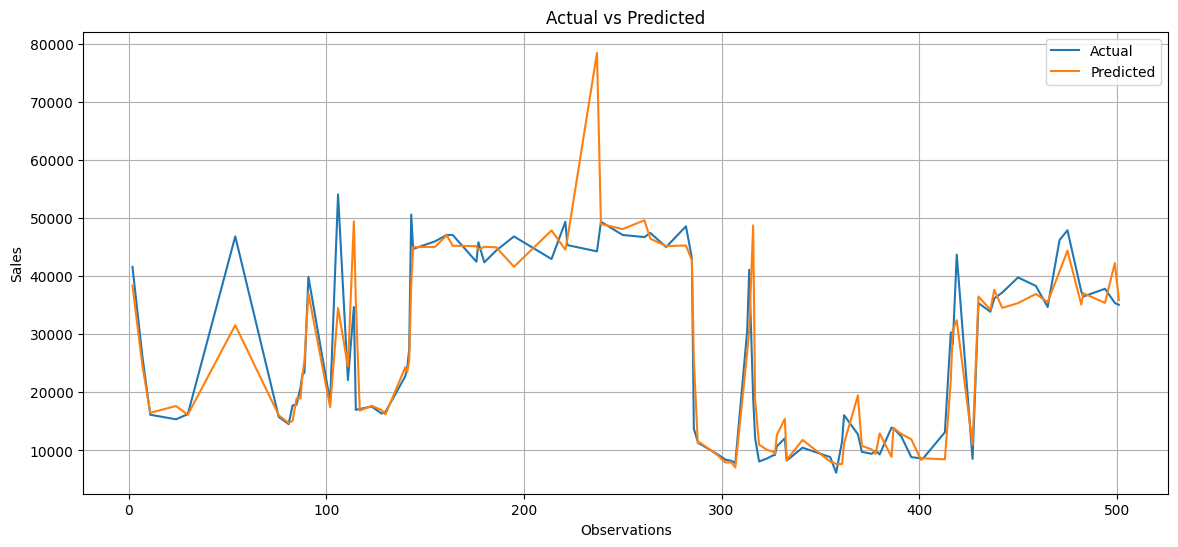

In [ ]:
y_pred = pd.Series(y_pred, index=y_test.index)
y_test_sorted=y_test.sort_index()
y_pred_sorted=y_pred.sort_index()

plt.figure(figsize=(14,6))
plt.plot(y_test_sorted[:100],label='Actual')
plt.plot(y_pred_sorted[:100],label='Predicted')
plt.legend()
plt.title('Actual vs Predicted')
plt.xlabel('Observations')
plt.ylabel('Sales')
plt.grid(True)
plt.show()

* The predicted values closely follow the actual sales trend, indicating strong
model performance.
* The model successfully captures variations and patterns in the data.
* Minor deviations exist but overall prediction accuracy is high.






## Gradient Boosting performed best with lowest RMSE and highest R² score, so it was selected as the final model.

 Business Insight:
 The model helps predict weekly sales, allowing Walmart to optimize inventory,
 manage supply chain, and improve revenue planning.

# Final Conclusion:
# The selected regression model effectively predicts sales based on key features.
# This can help businesses forecast demand and make data-driven decisions.

In [ ]:
import pickle
pickle.dump(gb,open("wallmart_sales.pkl","wb"))
pickle.dump(X.columns,open("columns.pkl","wb"))

In [ ]:
from google.colab import files
files.download("wallmart_sales.pkl")
files.download("columns.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>